In [2]:
"""
Customer Churn Prediction with KNN
Author: Francesco
Description: Predict whether a customer will churn or stay using KNN
"""

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

# Load the Telco customer churn dataset
print("Loading Telco customer churn dataset...")
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Inspect the loaded data
print(f"\nDataset type: {type(df)}")
print(f"Number of customers: {len(df)}")
print(f"Rows and columns: {df.shape}")
print(f"Target values before encoding: {df['Churn'].unique()}")

print("\nFirst few rows:")
print(df.head())

print("\nDataset info:")
df.info()

# Count the original text labels
print("\nChurn distribution before encoding:")
print(df["Churn"].value_counts())

# Convert the target labels to numbers:
# No = 0 (customer stayed), Yes = 1 (customer churned)
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

# Check the numeric labels
print("\nChurn distribution after encoding:")
print(df["Churn"].value_counts().sort_index())
print(f"No churn (0): {(df['Churn'] == 0).sum()}")
print(f"Churn (1): {(df['Churn'] == 1).sum()}")

Loading Telco customer churn dataset...

Dataset type: <class 'pandas.DataFrame'>
Number of customers: 7043
Rows and columns: (7043, 21)
Target values before encoding: <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

First few rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes 


BASIC STATISTICS
       SeniorCitizen       tenure  MonthlyCharges  TotalCharges        Churn
count    7043.000000  7043.000000     7043.000000        7032.0  7043.000000
mean        0.162147    32.371149       64.761692   2283.300441     0.265370
std         0.368612    24.559481       30.090047   2266.771362     0.441561
min         0.000000     0.000000       18.250000          18.8     0.000000
25%         0.000000     9.000000       35.500000        401.45     0.000000
50%         0.000000    29.000000       70.350000      1397.475     0.000000
75%         0.000000    55.000000       89.850000     3794.7375     1.000000
max         1.000000    72.000000      118.750000        8684.8     1.000000

MISSING VALUES
TotalCharges    11
dtype: int64


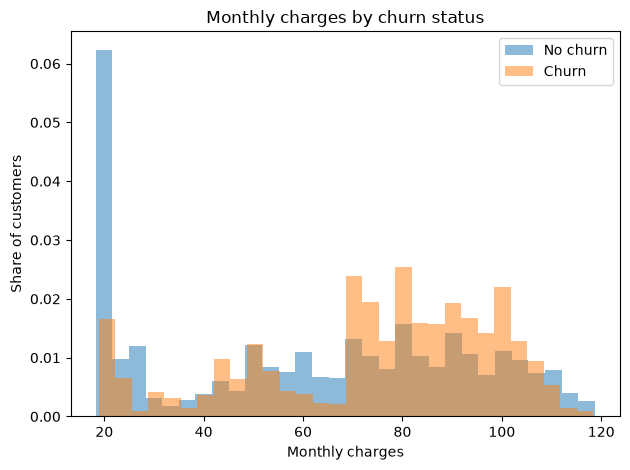

In [6]:
# Convert TotalCharges from text to numbers.
# Blank entries become missing values (NaN).
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].astype("string").str.strip(),
    errors='coerce'
)

# Basic statistics
print("\n" + "="*50)
print("BASIC STATISTICS")
print("="*50)
print(df.describe())
 
# Check for missing values
print("\n" + "="*50)
print("MISSING VALUES")
print("="*50)
missing = df.isnull().sum()
if missing.sum() == 0:
    print("✓ No missing values found!")
else:
    print(missing[missing > 0])
df["TotalCharges"] = df["TotalCharges"].fillna(0)
 
# Visualize feature distributions (select a few key features)
no_churn = df.loc[df['Churn'] == 0, 'MonthlyCharges']
churn = df.loc[df['Churn'] == 1, 'MonthlyCharges']

plt.hist(no_churn, bins=30, alpha=0.5, label='No churn', density=True)
plt.hist(churn, bins=30, alpha=0.5, label='Churn', density=True)

plt.xlabel('Monthly charges')
plt.ylabel('Share of customers')
plt.title('Monthly charges by churn status')
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
# Separate the target (what we want to predict)
y = df["Churn"]

# Keep customer details as features; exclude the target and ID
X = df.drop(columns=["Churn", "customerID"])

# Convert text categories into numeric columns
X = pd.get_dummies(X, dtype=int)

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (7043, 45)
Target shape: (7043,)


In [8]:
from sklearn.preprocessing import StandardScaler

In [9]:
# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Training rows: {X_train.shape[0]}")
print(f"Test rows: {X_test.shape[0]}")

# Scale the features for KNN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training rows: 5634
Test rows: 1409


In [11]:
# Create KNN classifier
# n_neighbors=5 means the model will look at the 5 nearest neighbors to make a prediction
 
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

 
print("KNN classifier trained successfully!")
print(f"Number of neighbors (k): {knn.n_neighbors}")
 
# Make predictions
y_train_pred = knn.predict(X_train_scaled)
y_test_pred = knn.predict(X_test_scaled)
 
print(f"\nTraining predictions: {len(y_train_pred)}")
print(f"Test predictions: {len(y_test_pred)}")

KNN classifier trained successfully!
Number of neighbors (k): 5

Training predictions: 5634
Test predictions: 1409


In [ ]:
# Make predictions for the test set
y_test_pred = knn.predict(X_test_scaled)

# Put the real and predicted diagnoses side by side
comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_test_pred
})

# Mark whether each prediction matches the churn outcomes
comparison["Correct?"] = comparison["Actual"] == comparison["Predicted"]

# Show the first 10 test cases
print(comparison.head(10))

   Actual  Predicted  Correct?
0       0          0      True
1       0          1     False
2       0          0      True
3       0          1     False
4       0          0      True
5       0          1     False
6       0          0      True
7       0          0      True
8       0          0      True
9       1          1      True


In [15]:
# Calculate metrics
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, pos_label=1)
test_recall = recall_score(y_test, y_test_pred, pos_label=1)
test_confusion = confusion_matrix(y_test, y_test_pred)
 
print("=== Model Performance ===")
print(f"\nTraining Accuracy: {train_accuracy:.4f} ({train_accuracy*100:.2f}%)")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"\nTest Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")
 
print("\n=== Confusion Matrix ===")
confusion_table = pd.DataFrame(
    test_confusion,
    index=["Actual no churn (0)", "Actual churn (1)"],
    columns=["Predicted no churn (0)", "Predicted churn (1)"]
)
print(confusion_table)
 
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["No churn (0)", "Churn (1)"]
))

=== Model Performance ===

Training Accuracy: 0.8339 (83.39%)
Test Accuracy: 0.7488 (74.88%)

Test Precision: 0.5272
Test Recall: 0.5187

=== Confusion Matrix ===
                     Predicted no churn (0)  Predicted churn (1)
Actual no churn (0)                     861                  174
Actual churn (1)                        180                  194
              precision    recall  f1-score   support

No churn (0)       0.83      0.83      0.83      1035
   Churn (1)       0.53      0.52      0.52       374

    accuracy                           0.75      1409
   macro avg       0.68      0.68      0.68      1409
weighted avg       0.75      0.75      0.75      1409




EXPERIMENTING WITH DIFFERENT K VALUES
K= 1: Accuracy=0.7126, Precision=0.4602, Recall=0.4786
K= 3: Accuracy=0.7381, Precision=0.5066, Recall=0.5107
K= 5: Accuracy=0.7488, Precision=0.5272, Recall=0.5187
K= 7: Accuracy=0.7530, Precision=0.5355, Recall=0.5241
K= 9: Accuracy=0.7686, Precision=0.5674, Recall=0.5401
K=11: Accuracy=0.7615, Precision=0.5543, Recall=0.5187
K=15: Accuracy=0.7729, Precision=0.5771, Recall=0.5401
K=20: Accuracy=0.7821, Precision=0.6031, Recall=0.5241
K=25: Accuracy=0.7757, Precision=0.5792, Recall=0.5668
K=30: Accuracy=0.7807, Precision=0.5959, Recall=0.5401

Best K value: 20 (Accuracy: 0.7821)

Saved visualization to 'knn_k_comparison.png'


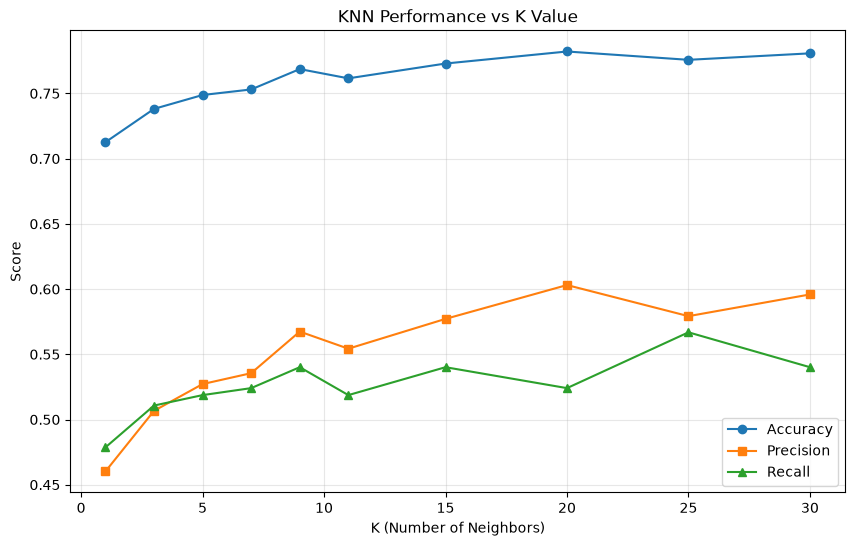

In [17]:
# Experiment with different K values
print("\n" + "="*50)
print("EXPERIMENTING WITH DIFFERENT K VALUES")
print("="*50)
 
k_values = [1, 3, 5, 7, 9, 11, 15, 20, 25, 30]
results = []
 
for k in k_values:
    # Create and train model
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled, y_train)
    
    # Make predictions
    y_pred_temp = knn_temp.predict(X_test_scaled)
    
    # Calculate accuracy
    acc = accuracy_score(y_test, y_pred_temp)
    prec = precision_score(y_test, y_pred_temp, pos_label=1)
    rec = recall_score(y_test, y_pred_temp, pos_label=1)
    
    results.append({
        'K': k,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec
    })
    
    print(f"K={k:2d}: Accuracy={acc:.4f}, Precision={prec:.4f}, Recall={rec:.4f}")
 
# Find best K
results_df = pd.DataFrame(results)
best_k = results_df.loc[results_df['Accuracy'].idxmax(), 'K']
print(f"\nBest K value: {best_k} (Accuracy: {results_df['Accuracy'].max():.4f})")
 
# Visualize results
plt.figure(figsize=(10, 6))
plt.plot(results_df['K'], results_df['Accuracy'], marker='o', label='Accuracy')
plt.plot(results_df['K'], results_df['Precision'], marker='s', label='Precision')
plt.plot(results_df['K'], results_df['Recall'], marker='^', label='Recall')
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Score')
plt.title('KNN Performance vs K Value')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('knn_k_comparison.png', dpi=150, bbox_inches='tight')
print("\nSaved visualization to 'knn_k_comparison.png'")
plt.show()

In [18]:
knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(X_train_scaled, y_train)

 
print("KNN classifier trained successfully!")
print(f"Number of neighbors (k): {knn.n_neighbors}")
 
# Make predictions
y_train_pred = knn.predict(X_train_scaled)
y_test_pred = knn.predict(X_test_scaled)
 
print(f"\nTraining predictions: {len(y_train_pred)}")
print(f"Test predictions: {len(y_test_pred)}")

KNN classifier trained successfully!
Number of neighbors (k): 20

Training predictions: 5634
Test predictions: 1409


In [20]:
# Calculate metrics
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, pos_label=1)
test_recall = recall_score(y_test, y_test_pred, pos_label=1)
test_confusion = confusion_matrix(y_test, y_test_pred)
 
print("=== Model Performance ===")
print(f"\nTraining Accuracy: {train_accuracy:.4f} ({train_accuracy*100:.2f}%)")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"\nTest Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")
 
print("\n=== Confusion Matrix ===")
confusion_table = pd.DataFrame(
    test_confusion,
    index=["Actual no churn (0)", "Actual churn (1)"],
    columns=["Predicted no churn (0)", "Predicted churn (1)"]
)
print(confusion_table)
 
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["No churn (0)", "Churn (1)"]
))

=== Model Performance ===

Training Accuracy: 0.8042 (80.42%)
Test Accuracy: 0.7821 (78.21%)

Test Precision: 0.6031
Test Recall: 0.5241

=== Confusion Matrix ===
                     Predicted no churn (0)  Predicted churn (1)
Actual no churn (0)                     906                  129
Actual churn (1)                        178                  196
              precision    recall  f1-score   support

No churn (0)       0.84      0.88      0.86      1035
   Churn (1)       0.60      0.52      0.56       374

    accuracy                           0.78      1409
   macro avg       0.72      0.70      0.71      1409
weighted avg       0.77      0.78      0.78      1409



Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


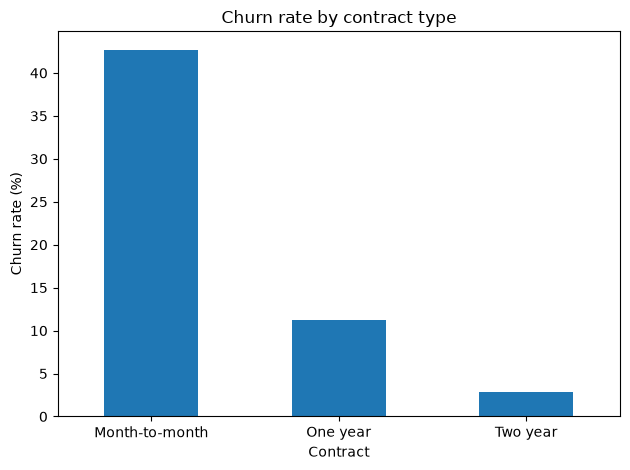

In [21]:
contract_churn_rate = (
    df.groupby("Contract")["Churn"].mean() * 100
).sort_values(ascending=False)

print(contract_churn_rate)

contract_churn_rate.plot(kind="bar")
plt.ylabel("Churn rate (%)")
plt.title("Churn rate by contract type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

TechSupport
No                     41.6
Yes                    15.2
No internet service     7.4
Name: Churn, dtype: float64


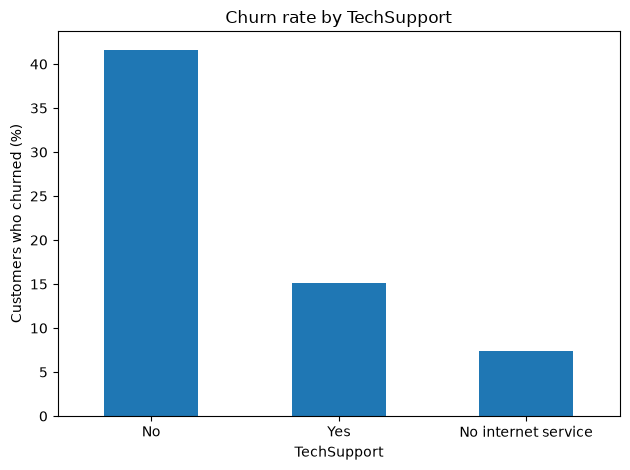

In [22]:
techsupport_churn_rate = (
    df.groupby("TechSupport")["Churn"].mean() * 100
).sort_values(ascending=False)

print(techsupport_churn_rate.round(1))

techsupport_churn_rate.plot(kind="bar")
plt.ylabel("Customers who churned (%)")
plt.title("Churn rate by TechSupport")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
segment_rates = (
    df.groupby(["Contract", "TechSupport"])["Churn"]
      .agg(["mean", "count"])
      .rename(columns={"mean": "churn_rate"})
)

segment_rates["churn_rate"] *= 100
print(segment_rates.sort_values("churn_rate", ascending=False).round(1))

                                    churn_rate  count
Contract       TechSupport                           
Month-to-month No                         50.4   2680
               Yes                        30.7    671
               No internet service        18.9    524
One year       No                         14.7    557
               Yes                        13.6    552
Two year       No                          5.9    236
               Yes                         3.5    821
One year       No internet service         2.5    364
Two year       No internet service         0.8    638
